# Classificazione Multiclasse sul Dataset UCI "Car Evaluation" (ID: 19)
**Corso:** Apprendimento Automatico e Apprendimento Profondo  
**Studente:** Salvatore Dimino — **Matricola:** 0322600129  
**Repository di consegna:** `https://github.com/NScarpato79/apprendimento_automatico_e_apprendimento_profondo.git`

Questo notebook implementa l'intera pipeline sperimentale richiesta dalla traccia:
1. Caricamento del dataset **Car Evaluation** (UCI Machine Learning Repository, ID: 19) e partizionamento stratificato **70% Train / 20% Validation / 10% Test** (`SEED = 42`).
2. Preprocessing senza *data leakage* (codifica ordinale semantica + `StandardScaler` adattato solo sul Training Set).
3. **Task 1:** Analisi delle Componenti Principali (**PCA**) e visualizzazioni (`pca_variance.png` e `pca_scatter_2d.png`).
4. **Task 2, 3 e 4:** Addestramento di modelli *shallow* (*Decision Tree*, *Random Forest*, *SVM RBF*, *KNN*), calcolo delle metriche (*Accuracy*, *Precision*, *Recall*, *F1-Score*, *ROC AUC*) e visualizzazione di *Confusion Matrix* e *ROC AUC Curve*.
5. **Task 5a:** Rete neurale *Multi-Layer Perceptron* (**MLP**) in PyTorch sugli stessi dati e sullo stesso split 70/20/10, con confronto finale su Test Set.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, StandardScaler, label_binarize
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    auc,
    confusion_matrix,
    classification_report,
)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
os.makedirs("outputs", exist_ok=True)
print("Setup completato. SEED =", SEED)

Setup completato. SEED = 42


## 0. Caricamento del Dataset UCI "Car Evaluation" (ID: 19)

In [2]:
try:
    from ucimlrepo import fetch_ucirepo

    car_eval = fetch_ucirepo(id=19)
    X = car_eval.data.features.copy()
    y_raw = car_eval.data.targets.iloc[:, 0].copy()
except Exception:
    url = (
        "https://archive.ics.uci.edu/ml/"
        "machine-learning-databases/car/car.data"
    )
    cols = [
        "buying", "maint", "doors", "persons",
        "lug_boot", "safety", "class",
    ]
    df_car = pd.read_csv(url, header=None, names=cols)
    X = df_car.drop(columns=["class"]).copy()
    y_raw = df_car["class"].copy()

categories_order = [
    ["low", "med", "high", "vhigh"],  # buying
    ["low", "med", "high", "vhigh"],  # maint
    ["2", "3", "4", "5more"],         # doors
    ["2", "4", "more"],               # persons
    ["small", "med", "big"],          # lug_boot
    ["low", "med", "high"],           # safety
]
class_names = ["unacc", "acc", "good", "vgood"]
class_to_int = {label: idx for idx, label in enumerate(class_names)}

y = y_raw.astype(str).str.strip().map(class_to_int)
for col in X.columns:
    X[col] = X[col].astype(str).str.strip()

print("Dataset: Car Evaluation (UCI ID: 19)")
print("Dimensioni X:", X.shape)
print("Valori mancanti in X:", X.isna().sum().sum(), "| in y:", y.isna().sum())
print(
    "Distribuzione classi:\n",
    y.map({v: k for k, v in class_to_int.items()}).value_counts(),
)

Dataset: Car Evaluation (UCI ID: 19)
Dimensioni X: (1728, 6)
Valori mancanti in X: 0 | in y: 0
Distribuzione classi:
 class
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64


## 1. Split Stratificato 70% Train / 20% Validation / 10% Test e Preprocessing

In [3]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=(1.0 / 3.0),
    random_state=SEED,
    stratify=y_temp,
)

print(f"Split -> Train: {len(X_train)}, Val: {len(X_val)}, Test: {len(X_test)}")

encoder = OrdinalEncoder(categories=categories_order)
scaler = StandardScaler()

X_train_enc = encoder.fit_transform(X_train)
X_val_enc = encoder.transform(X_val)
X_test_enc = encoder.transform(X_test)

X_train_scaled = scaler.fit_transform(X_train_enc)
X_val_scaled = scaler.transform(X_val_enc)
X_test_scaled = scaler.transform(X_test_enc)

Split -> Train: 1209, Val: 346, Test: 173


## 2. Task 1 — Analisi delle Componenti Principali (PCA)

Varianza spiegata per componente: [0.1784 0.1738 0.1664 0.1644 0.1608 0.1561]
Varianza cumulativa per componente: [0.1784 0.3523 0.5187 0.6831 0.8439 1.    ]
Componenti necessarie per >= 90% varianza spiegata: 6


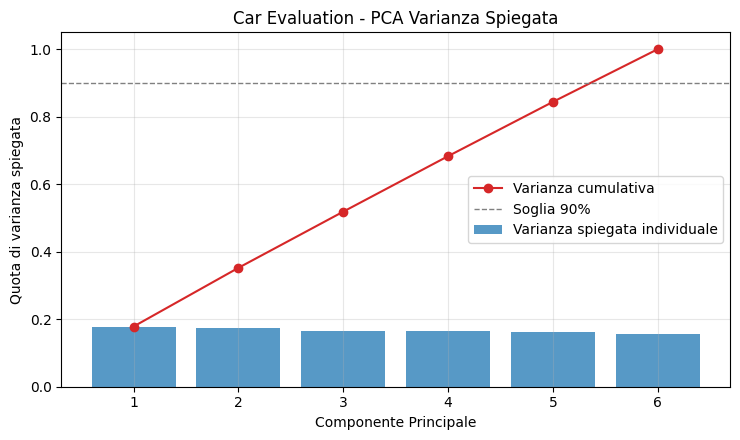

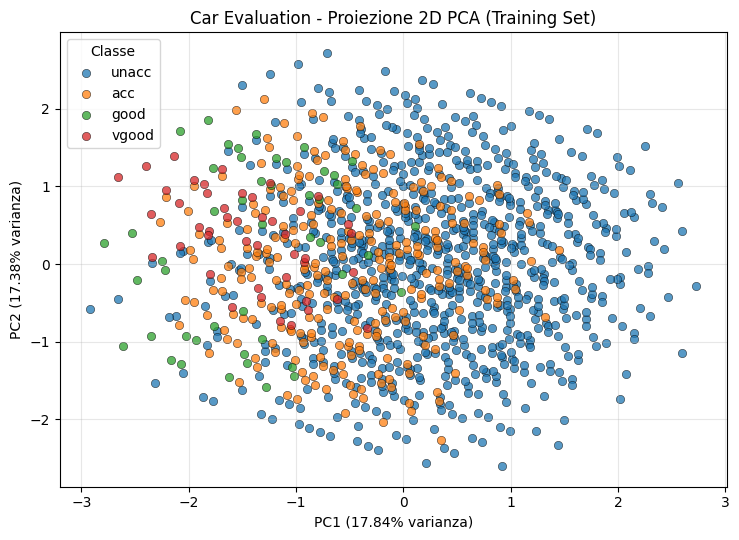

In [4]:
pca = PCA(random_state=SEED)
X_train_pca = pca.fit_transform(X_train_scaled)
X_val_pca = pca.transform(X_val_scaled)
X_test_pca = pca.transform(X_test_scaled)

explained_var = pca.explained_variance_ratio_
cum_explained_var = np.cumsum(explained_var)
n_comp_90 = int(np.argmax(cum_explained_var >= 0.90) + 1)

print("Varianza spiegata per componente:", np.round(explained_var, 4))
print("Varianza cumulativa per componente:", np.round(cum_explained_var, 4))
print(f"Componenti necessarie per >= 90% varianza spiegata: {n_comp_90}")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
comp_idx = np.arange(1, len(explained_var) + 1)
ax.bar(
    comp_idx,
    explained_var,
    alpha=0.75,
    label="Varianza spiegata individuale",
)
ax.plot(
    comp_idx,
    cum_explained_var,
    marker="o",
    color="tab:red",
    label="Varianza cumulativa",
)
ax.axhline(
    0.90, color="gray", linestyle="--", linewidth=1, label="Soglia 90%"
)
ax.set_xlabel("Componente Principale")
ax.set_ylabel("Quota di varianza spiegata")
ax.set_title("Car Evaluation - PCA Varianza Spiegata")
ax.set_xticks(comp_idx)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("outputs/pca_variance.png", dpi=300)
plt.show()

fig, ax = plt.subplots(figsize=(7.5, 5.5))
for cls_id, cls_label in enumerate(class_names):
    mask = y_train.values == cls_id
    ax.scatter(
        X_train_pca[mask, 0],
        X_train_pca[mask, 1],
        alpha=0.75,
        edgecolor="k",
        linewidth=0.4,
        label=cls_label,
    )
ax.set_xlabel(f"PC1 ({explained_var[0] * 100:.2f}% varianza)")
ax.set_ylabel(f"PC2 ({explained_var[1] * 100:.2f}% varianza)")
ax.set_title("Car Evaluation - Proiezione 2D PCA (Training Set)")
ax.legend(title="Classe")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("outputs/pca_scatter_2d.png", dpi=300)
plt.show()

## 3. Task 2, 3 e 4 — Classificatori Shallow, Metriche, Confusion Matrix e ROC AUC


--- Classification Report: Decision Tree ---
              precision    recall  f1-score   support

       unacc       0.95      1.00      0.97       121
         acc       0.94      0.82      0.87        38
        good       1.00      0.71      0.83         7
       vgood       1.00      1.00      1.00         7

    accuracy                           0.95       173
   macro avg       0.97      0.88      0.92       173
weighted avg       0.95      0.95      0.95       173



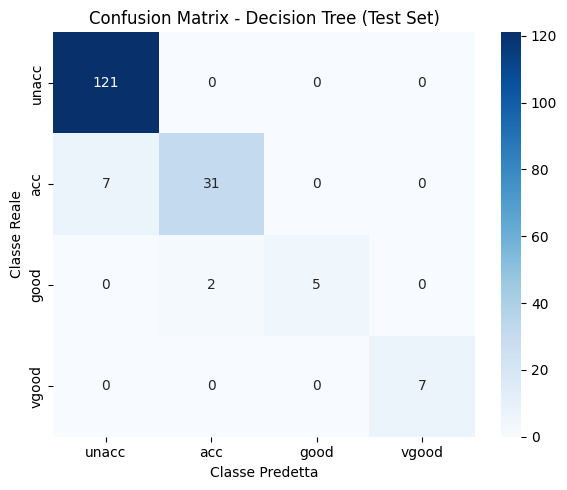


--- Classification Report: Random Forest ---
              precision    recall  f1-score   support

       unacc       0.98      0.99      0.98       121
         acc       0.95      0.92      0.93        38
        good       1.00      0.71      0.83         7
       vgood       0.88      1.00      0.93         7

    accuracy                           0.97       173
   macro avg       0.95      0.91      0.92       173
weighted avg       0.97      0.97      0.96       173



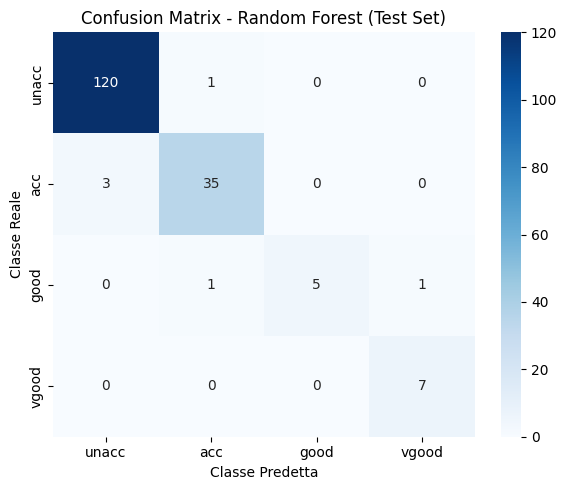


--- Classification Report: SVM (RBF) ---
              precision    recall  f1-score   support

       unacc       0.99      1.00      1.00       121
         acc       0.97      0.97      0.97        38
        good       1.00      0.71      0.83         7
       vgood       0.88      1.00      0.93         7

    accuracy                           0.98       173
   macro avg       0.96      0.92      0.93       173
weighted avg       0.98      0.98      0.98       173



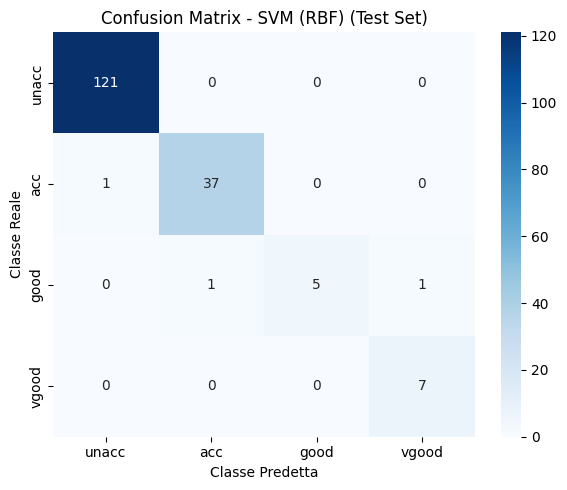


--- Classification Report: KNN (k=7) ---
              precision    recall  f1-score   support

       unacc       0.96      1.00      0.98       121
         acc       0.94      0.87      0.90        38
        good       1.00      0.57      0.73         7
       vgood       0.88      1.00      0.93         7

    accuracy                           0.95       173
   macro avg       0.94      0.86      0.89       173
weighted avg       0.95      0.95      0.95       173



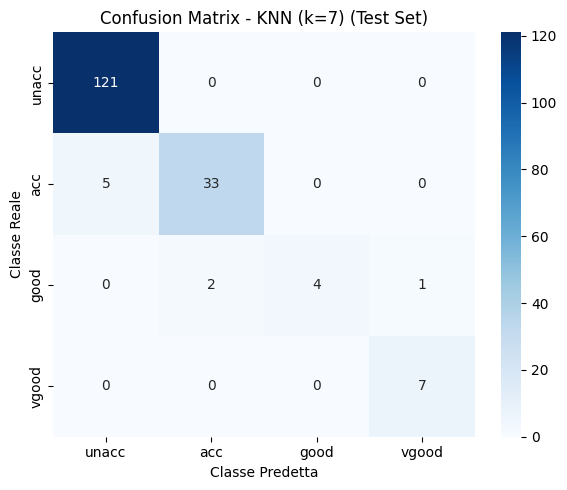

In [5]:
models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=10, random_state=SEED),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=SEED
    ),
    "SVM (RBF)": SVC(
        C=5.0, kernel="rbf", probability=True, random_state=SEED
    ),
    "KNN (k=7)": KNeighborsClassifier(n_neighbors=7),
}

n_classes = len(class_names)
y_test_bin = label_binarize(y_test, classes=list(range(n_classes)))

results = []
prob_predictions = {}

for name, clf in models.items():
    clf.fit(X_train_scaled, y_train)
    val_acc = accuracy_score(y_val, clf.predict(X_val_scaled))

    y_test_pred = clf.predict(X_test_scaled)
    y_test_proba = clf.predict_proba(X_test_scaled)
    prob_predictions[name] = y_test_proba

    acc = accuracy_score(y_test, y_test_pred)
    prec = precision_score(
        y_test, y_test_pred, average="weighted", zero_division=0
    )
    rec = recall_score(
        y_test, y_test_pred, average="weighted", zero_division=0
    )
    f1 = f1_score(
        y_test, y_test_pred, average="weighted", zero_division=0
    )
    roc_auc = roc_auc_score(
        y_test_bin, y_test_proba, multi_class="ovr", average="weighted"
    )

    results.append(
        {
            "Modello": name,
            "Val Accuracy": round(val_acc, 4),
            "Test Accuracy": round(acc, 4),
            "Precision": round(prec, 4),
            "Recall": round(rec, 4),
            "F1-Score": round(f1, 4),
            "ROC AUC (OvR weighted)": round(roc_auc, 4),
        }
    )

    print(f"\n--- Classification Report: {name} ---")
    print(
        classification_report(
            y_test, y_test_pred, target_names=class_names, zero_division=0
        )
    )

    cm = confusion_matrix(y_test, y_test_pred)
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax,
    )
    ax.set_xlabel("Classe Predetta")
    ax.set_ylabel("Classe Reale")
    ax.set_title(f"Confusion Matrix - {name} (Test Set)")
    plt.tight_layout()
    safe_name = (
        name.lower()
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
        .replace("=", "")
    )
    plt.savefig(f"outputs/cm_{safe_name}.png", dpi=300)
    plt.show()

## 4. Task 5a — Rete Neurale Multiclasse (PyTorch MLP) sugli Stessi Dati e Split


--- Classification Report: Neural Net (PyTorch MLP) ---
              precision    recall  f1-score   support

       unacc       0.98      1.00      0.99       121
         acc       1.00      0.95      0.97        38
        good       1.00      1.00      1.00         7
       vgood       1.00      1.00      1.00         7

    accuracy                           0.99       173
   macro avg       1.00      0.99      0.99       173
weighted avg       0.99      0.99      0.99       173



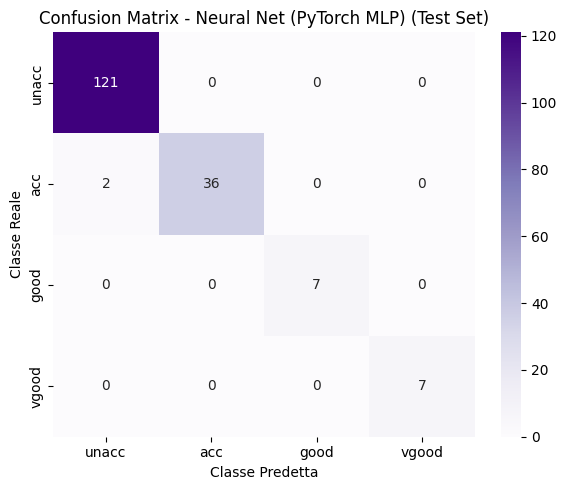

In [6]:
try:
    import torch
    import torch.nn as nn
    from torch.utils.data import TensorDataset, DataLoader

    torch.manual_seed(SEED)
    np.random.seed(SEED)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    train_ds = TensorDataset(
        torch.tensor(X_train_scaled, dtype=torch.float32),
        torch.tensor(y_train.values, dtype=torch.long),
    )
    train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)

    class CarMLP(nn.Module):
        def __init__(self, in_features, num_classes):
            super().__init__()
            self.net = nn.Sequential(
                nn.Linear(in_features, 64),
                nn.ReLU(),
                nn.Dropout(0.2),
                nn.Linear(64, 64),
                nn.ReLU(),
                nn.Dropout(0.2),
                nn.Linear(64, num_classes),
            )

        def forward(self, x):
            return self.net(x)

    mlp = CarMLP(X_train_scaled.shape[1], n_classes).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        mlp.parameters(), lr=1e-3, weight_decay=1e-4
    )

    X_val_t = torch.tensor(
        X_val_scaled, dtype=torch.float32, device=device
    )
    y_val_t = torch.tensor(
        y_val.values, dtype=torch.long, device=device
    )

    best_val_loss = float("inf")
    best_state = None
    epochs = 120

    for epoch in range(epochs):
        mlp.train()
        for bx, by in train_loader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            logits = mlp(bx)
            loss = criterion(logits, by)
            loss.backward()
            optimizer.step()

        mlp.eval()
        with torch.no_grad():
            val_logits = mlp(X_val_t)
            val_loss = criterion(val_logits, y_val_t).item()
            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_state = {
                    k: v.cpu().clone() for k, v in mlp.state_dict().items()
                }

    if best_state is not None:
        mlp.load_state_dict({k: v.to(device) for k, v in best_state.items()})

    mlp.eval()
    with torch.no_grad():
        val_probs = torch.softmax(mlp(X_val_t), dim=1).cpu().numpy()
        val_preds = np.argmax(val_probs, axis=1)

        X_test_t = torch.tensor(
            X_test_scaled, dtype=torch.float32, device=device
        )
        y_test_proba_nn = torch.softmax(mlp(X_test_t), dim=1).cpu().numpy()
        y_test_pred_nn = np.argmax(y_test_proba_nn, axis=1)

    nn_name = "Neural Net (PyTorch MLP)"
    prob_predictions[nn_name] = y_test_proba_nn

    results.append(
        {
            "Modello": nn_name,
            "Val Accuracy": round(accuracy_score(y_val, val_preds), 4),
            "Test Accuracy": round(accuracy_score(y_test, y_test_pred_nn), 4),
            "Precision": round(
                precision_score(
                    y_test, y_test_pred_nn, average="weighted", zero_division=0
                ),
                4,
            ),
            "Recall": round(
                recall_score(
                    y_test, y_test_pred_nn, average="weighted", zero_division=0
                ),
                4,
            ),
            "F1-Score": round(
                f1_score(
                    y_test, y_test_pred_nn, average="weighted", zero_division=0
                ),
                4,
            ),
            "ROC AUC (OvR weighted)": round(
                roc_auc_score(
                    y_test_bin,
                    y_test_proba_nn,
                    multi_class="ovr",
                    average="weighted",
                ),
                4,
            ),
        }
    )

    print(f"\n--- Classification Report: {nn_name} ---")
    print(
        classification_report(
            y_test, y_test_pred_nn, target_names=class_names, zero_division=0
        )
    )

    cm_nn = confusion_matrix(y_test, y_test_pred_nn)
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(
        cm_nn,
        annot=True,
        fmt="d",
        cmap="Purples",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax,
    )
    ax.set_xlabel("Classe Predetta")
    ax.set_ylabel("Classe Reale")
    ax.set_title(f"Confusion Matrix - {nn_name} (Test Set)")
    plt.tight_layout()
    plt.savefig("outputs/cm_pytorch_mlp.png", dpi=300)
    plt.show()

except ImportError:
    print("PyTorch non disponibile: installare torch per il modello neurale.")

## 5. Curve ROC AUC Multiclasse e Tabella Comparativa Finale

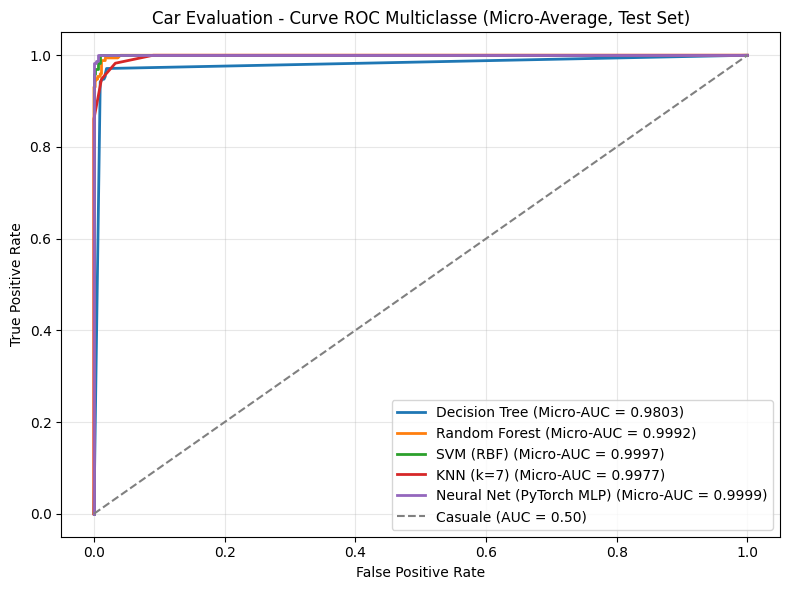


=== RISULTATI FINALI SUL TEST SET (CAR EVALUATION) ===
                 Modello  Val Accuracy  Test Accuracy  Precision  Recall  F1-Score  ROC AUC (OvR weighted)
Neural Net (PyTorch MLP)        0.9942         0.9884     0.9886  0.9884    0.9883                  1.0000
               SVM (RBF)        0.9827         0.9827     0.9834  0.9827    0.9819                  0.9999
           Random Forest        0.9740         0.9653     0.9660  0.9653    0.9644                  0.9992
               KNN (k=7)        0.9509         0.9538     0.9546  0.9538    0.9510                  0.9982
           Decision Tree        0.9595         0.9480     0.9484  0.9480    0.9458                  0.9514


In [7]:
fig, ax = plt.subplots(figsize=(8, 6))
for name, y_proba in prob_predictions.items():
    fpr_micro, tpr_micro, _ = roc_curve(y_test_bin.ravel(), y_proba.ravel())
    roc_micro_auc = auc(fpr_micro, tpr_micro)
    ax.plot(
        fpr_micro,
        tpr_micro,
        linewidth=2,
        label=f"{name} (Micro-AUC = {roc_micro_auc:.4f})",
    )

ax.plot(
    [0, 1], [0, 1], linestyle="--", color="gray", label="Casuale (AUC = 0.50)"
)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title(
    "Car Evaluation - Curve ROC Multiclasse (Micro-Average, Test Set)"
)
ax.legend(loc="lower right")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("outputs/roc_curves_multiclass.png", dpi=300)
plt.show()

results_df = pd.DataFrame(results).sort_values(
    by="ROC AUC (OvR weighted)", ascending=False
)
print("\n=== RISULTATI FINALI SUL TEST SET (CAR EVALUATION) ===")
print(results_df.to_string(index=False))
results_df.to_csv("outputs/risultati_car_evaluation.csv", index=False)